<div dir="rtl" style="text-align:right">

# ميزان الريع · Mizan Al-Rai
## منصة التنبؤ الذكي بالتدفقات المالية للوقف
### كم يصرف الناظر هذا العام دون أن يأكل الأصل؟ وكيف يوزّعه على المصارف؟

**الفريق:** عبدالله عبدالرحمن عبدالله العضياني · ثامر خالد صالح الغامدي

**سؤال القرار:** ما معدل الصرف السنوي الذي يحفظ القيمة *الحقيقية* (بعد التضخم) لأصل الوقف خلال عشر سنوات
بدرجة ثقة يحددها الناظر، وكيف يُوزَّع هذا المبلغ على المصارف الشرعية مع احترام شروط الواقفين؟

**البيانات (حقيقية ومفتوحة من القطاع غير الربحي فقط):**
1. الهيئة العامة للأوقاف — 18 مجموعة بيانات على منصة البيانات المفتوحة الوطنية (15,305 مصرفاً وقفياً في 13 منطقة، الشهادات الوقفية، المستفيدون…).
2. السوق المالية السعودية (تداول) — أسعار وحدات **26 صندوقاً استثمارياً وقفياً** مرخصاً من هيئة السوق المالية (2018–2026).

**التشغيل:** `python scripts/run_analysis.py` يعيد بناء كل المخرجات من البيانات الخام في ثوانٍ. هذا الدفتر يستدعي **الدوال نفسها** خطوة بخطوة ويشرحها.

</div>

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Image, display
from waqf import pipeline, config, clean, forecast
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 160)
res = pipeline.Results()
def show(name): display(Image(filename=str(config.FIGURES / name), width=820))

<div dir="rtl" style="text-align:right">

## 1. البيانات الخام والتحقق من سلامتها
بوابة البيانات المفتوحة وموقع تداول يحجبان الطلبات الآلية (جدار حماية WAF)، لذلك جُمعت البيانات عبر واجهات المعاينة
الرسمية داخل المتصفح وحُفظت كلقطات ثابتة في `data_raw/` مع **فحوص سلامة**: عدد صفوف كل جدول كما تعلنه البوابة،
و(عدد الملاحظات + مجموع الأسعار) لكل صندوق. أي تعديل في الملفات يوقف التشغيل فوراً (مختبر في `tests/`).

</div>

In [2]:
raw = pipeline.step_ingest(res)
display(res.tables["data_manifest"])
print("GASA tables:", len(raw.gasa), "| funds:", raw.prices.symbol.nunique(), "| price observations:", len(raw.prices))

,file,sha256,bytes
0,data_raw/gasa/gasa_open_data_snapshot.json,21b48a6f7799989fc4c00b595fc6585f281bac37385bf5f469b05bc2bc6409cc,15307
1,data_raw/tadawul/waqf_funds_universe.csv,09142ef83b16fc328a7b8dd66032c5b8e8bb9a5be25207d56cf9914b9cca2dfb,3149
2,data_raw/tadawul/waqf_funds_month_end_prices.csv,f98497db77e8d45c04ac21c8ad8780f97a3cd66762943da66a03e3ad5a1c6f2e,26863


GASA tables: 18 | funds: 26 | price observations: 1053


<div dir="rtl" style="text-align:right">

## 2. تنظيف البيانات وتوثيقه
كل قاعدة تنظيف تُسجَّل آلياً في سجل التنظيف (المصدر، القاعدة، عدد الصفوف المتأثرة). أبرز المشكلات الحقيقية التي عولجت:
- **تهجئات متعددة للمصرف نفسه** (`تعلم العلم وتعليمه` / `العلم وتعليمه`، `اضحيه`، `الدعوه`) ← طيّ إملائي عربي + قاموس مصارف موحّد.
- **علامة BOM** في رؤوس الأعمدة، ومسافات زائدة، وأرقام بفواصل آلاف (`' 8,514,665 '`)، وسنة نصية (`2022 وماقبلها`).
- **أسعار إطلاق ثابتة** قبل بدء الاستثمار (10.0000 لعدة أرباع) ← حُذفت.
- **أسعار مكررة متجمدة** وسط السلسلة ← عوملت كقيم مفقودة.
- **فجوات إفصاح ربعي** ← استيفاء لوغاريتمي خطي مُعلَّم (`imputed`).
- **حقل صافي الأصول = 0** في أغلب الأشهر ← أُسقط لعدم موثوقيته.
- **توزيعات مخفية:** سعر الوحدة يهبط عند توزيع العوائد على المستفيدين (كل يوليو في صناديق الإنماء) ← كشفناها آلياً (القسم 4).

</div>

In [3]:
c = pipeline.step_clean(raw, res)
display(res.tables["cleaning_log"])

,source,rule,rows_affected,detail
0,GASA disbursements,Strip BOM & 'منطقة' prefix; unify region names,157,13 regions
1,GASA disbursements,"Arabic orthographic folding (أ/إ/آ→ا, ة→ه, ى→ي) + alias map",157,"25 raw labels → 24 canonical masarif (1 merged, e.g. 'تعلم العلم وتعليمه' → 'العلم وتعليمه')"
2,GASA rewards,Parse '2022 وماقبلها' as 2022 and flag as cumulative-to-date,1,"kept, excluded from per-year trend"
3,GASA rewards,"Parse amounts with thousands separators and padding (' 8,514,665 ')",3,
4,GASA inspections/reports,Trim trailing spaces in category labels,5,
5,Tadawul prices,Stale repeated price set to missing then interpolated,4,012012: 2026-05; 012054: 2024-09; 045010: 2024-05; 045011: 2024-08
6,Tadawul prices,Drop pre-investment par prices (unchanged launch price),18,030030; 045007; 045008; 045009; 045010
7,Tadawul prices,Quarterly-reporting gaps filled by log-linear interpolation (flagged),62,045007; 045008; 045009; 045010; 045011
8,Tadawul prices,Exclude funds with < 12 months of history,12,"011171, 012068"
9,Tadawul prices,Separate distributing funds (price return excludes payouts) from the index,453,12 distributing funds kept for comparison


In [4]:
# مثال قبل/بعد: من 25 تسمية خام إلى 24 مصرفاً موحّداً
raw_labels = sorted({m for t in raw.gasa.values() if "counts" in t for _, m, _ in t["counts"]})
mapping = pd.DataFrame({"raw_label": raw_labels})
mapping["canonical"] = mapping.raw_label.map(lambda s: clean.MASRAF_MAP[clean.fold_arabic(s)][1])
display(mapping[mapping.raw_label != mapping.canonical])
print(c["fund_prices"].flag.value_counts().to_dict())

,raw_label,canonical
0,اضحيه,الأضاحي
1,اطعام الطعام,إطعام الطعام
2,افطار صائم,إفطار الصائم
3,الارامل,الأرامل
4,الاغوات,الأغوات
5,الايتام,الأيتام
9,الدعوه,الدعوة
12,القران الكريم,القرآن الكريم
14,اوجه البر,أوجه البر
15,تعلم العلم وتعليمه,العلم وتعليمه


{'observed': 1031, 'imputed': 62, 'stale_fixed': 4}


<div dir="rtl" style="text-align:right">

## 3. صورة القطاع: أين تذهب الأوقاف اليوم؟

</div>

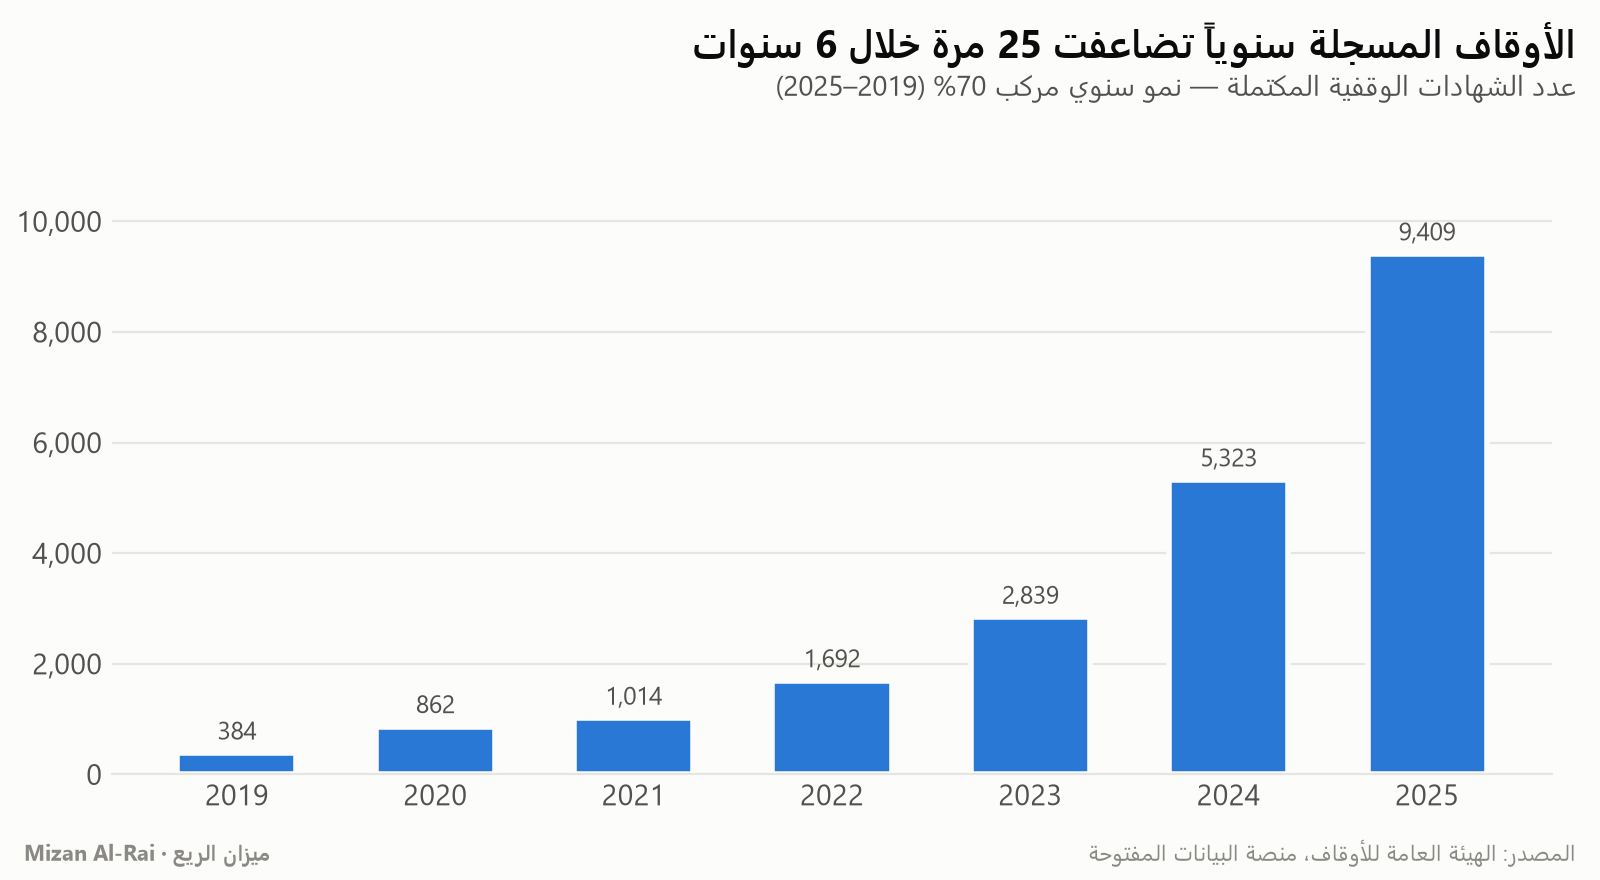

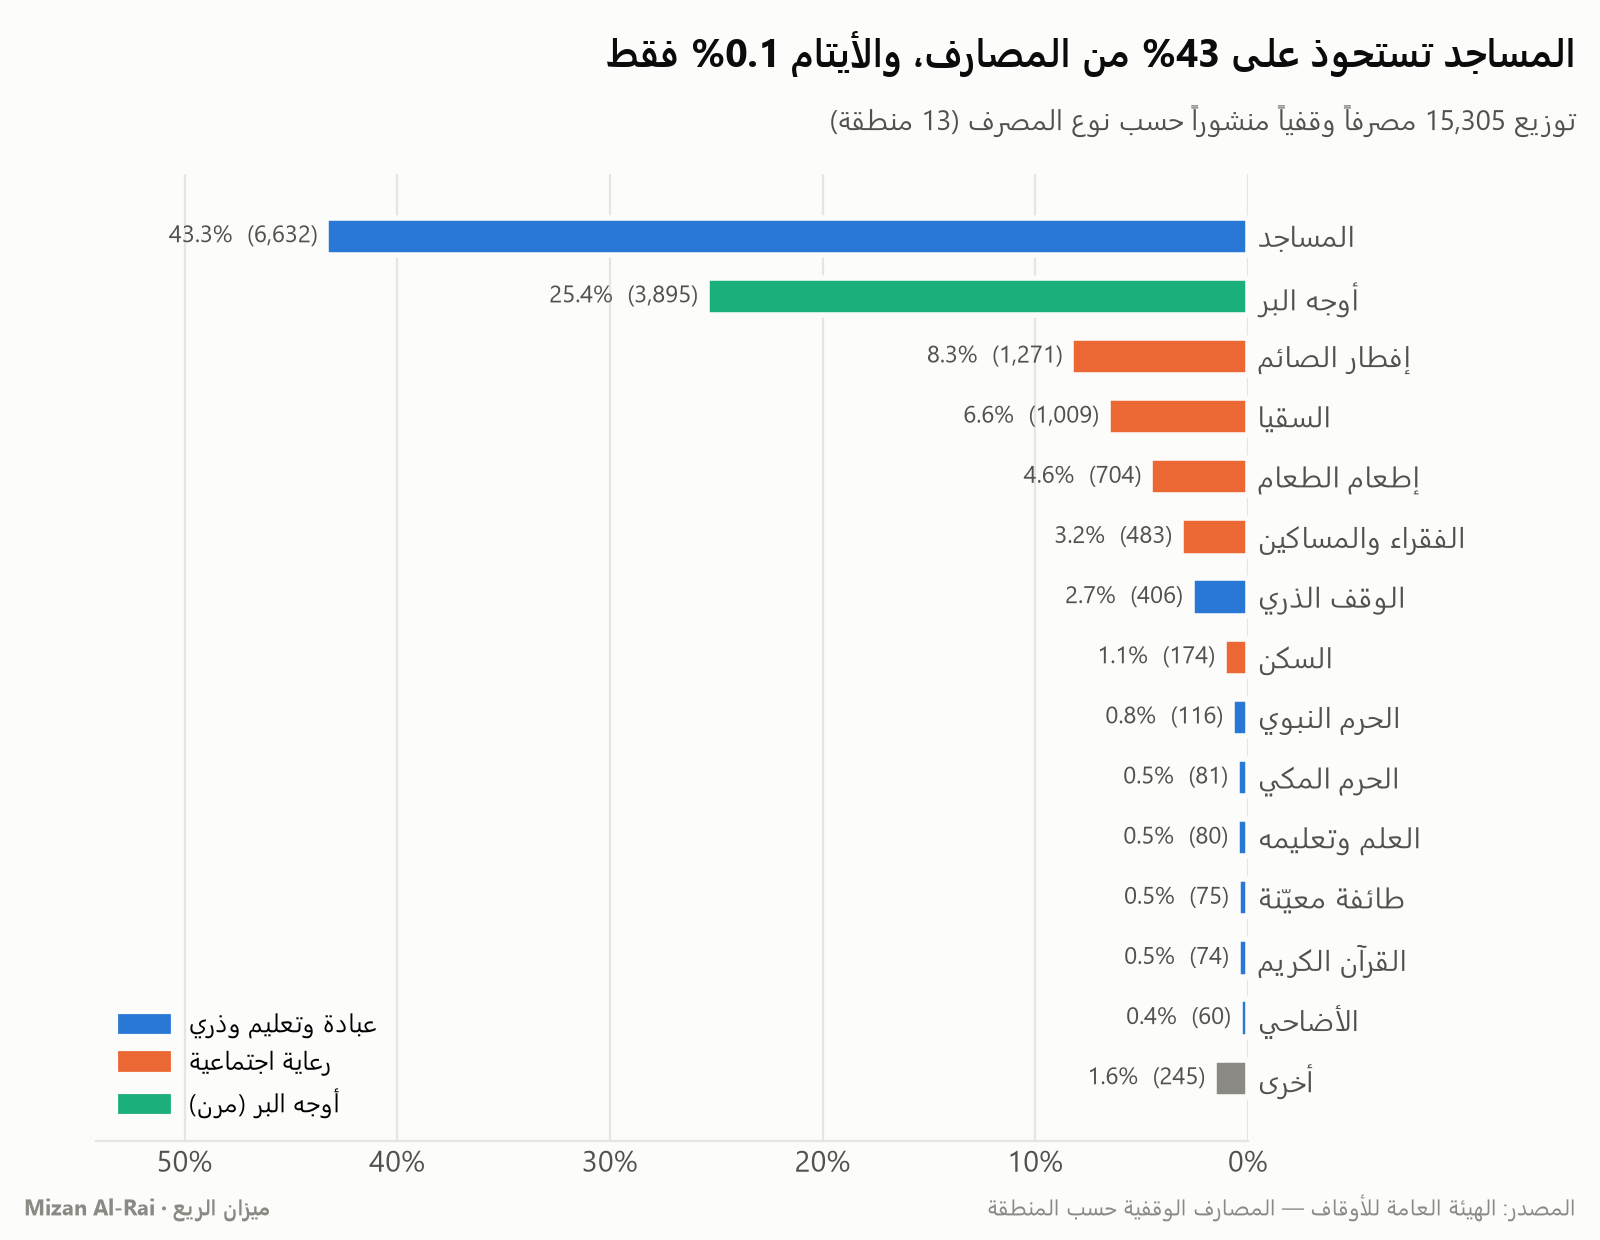

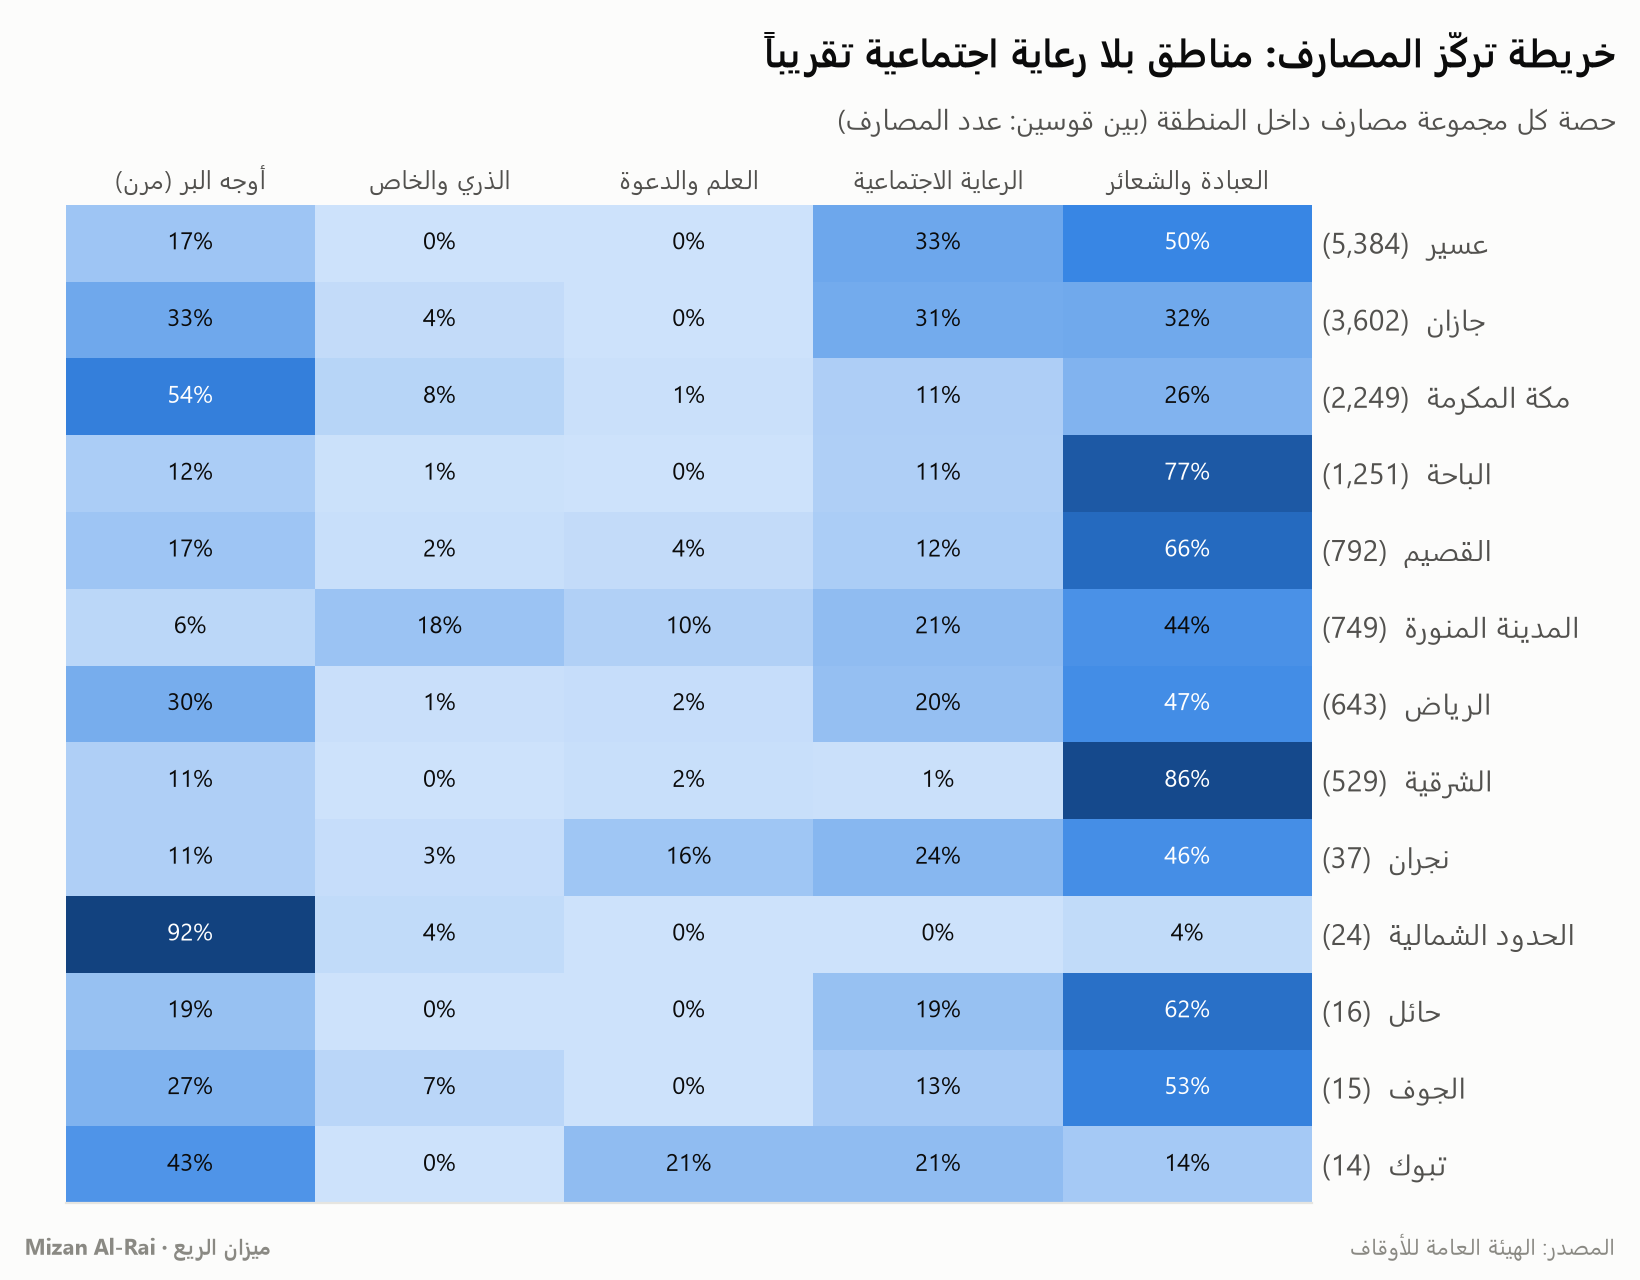

المساجد 43.3% | أوجه البر (مرن) 25.4% | الأيتام 0.10% | الأرامل 0.04%


,region_ar,waqf_designations,flexible_share,social_share,hhi,top_masraf,top_share
0,عسير,5384,0.165,0.334,0.327,mosques,0.499
1,جازان,3602,0.327,0.311,0.252,general_charity,0.327
2,مكة المكرمة,2249,0.539,0.112,0.344,general_charity,0.539
3,الباحة,1251,0.119,0.106,0.610,mosques,0.767
4,القصيم,792,0.165,0.119,0.410,mosques,0.614
5,المدينة المنورة,749,0.064,0.212,0.116,mosques,0.230
6,الرياض,643,0.297,0.196,0.281,mosques,0.412
7,الشرقية,529,0.106,0.011,0.735,mosques,0.851
8,نجران,37,0.108,0.243,0.191,mosques,0.378
9,الحدود الشمالية,24,0.917,0.000,0.844,general_charity,0.917


In [5]:
sec = pipeline.step_sector(c, res)
k = res.key["sector"]
show("fig01_sector_growth.png"); show("fig02_masarif_national.png"); show("fig03_region_heatmap.png")
print(f"المساجد {k['mosques_share']:.1%} | أوجه البر (مرن) {k['flexible_share']:.1%} | الأيتام {k['orphans_share']:.2%} | الأرامل {k['widows_share']:.2%}")
display(sec["regions"][["region_ar","waqf_designations","flexible_share","social_share","hhi","top_masraf","top_share"]].round(3))

<div dir="rtl" style="text-align:right">

**قراءة:** نمو تسجيل الأوقاف استثنائي (≈70% سنوياً)، لكن المصارف شديدة التركّز: المساجد وحدها 43%، بينما الأيتام والأرامل
أقل من 0.2% مجتمعين. الحصة المرنة (**أوجه البر 25%**) هي الرافعة الوحيدة التي يملك الناظر توجيهها دون مخالفة شرط واقف.

</div>

<div dir="rtl" style="text-align:right">

## 4. أداء الأصول الوقفية: مؤشر صناديق الوقف السعودية
بنينا مؤشراً متساوي الأوزان من **الصناديق التراكمية** المؤهلة (≥ 12 شهراً). اكتشاف مهم أثناء التنظيف: هبوط متزامن في
صناديق مدير واحد بينما صناديق المديرين الآخرين صاعدة = **توزيع عوائد** وليس خسارة. قدّرنا حجمه بالفجوة عن متوسط الأقران،
فحصلنا على مؤشرين: *عائد السعر* (ما يبقى للأصل) و*العائد الكلي المقدَّر* (ما يولّده الأصل فعلاً).

</div>

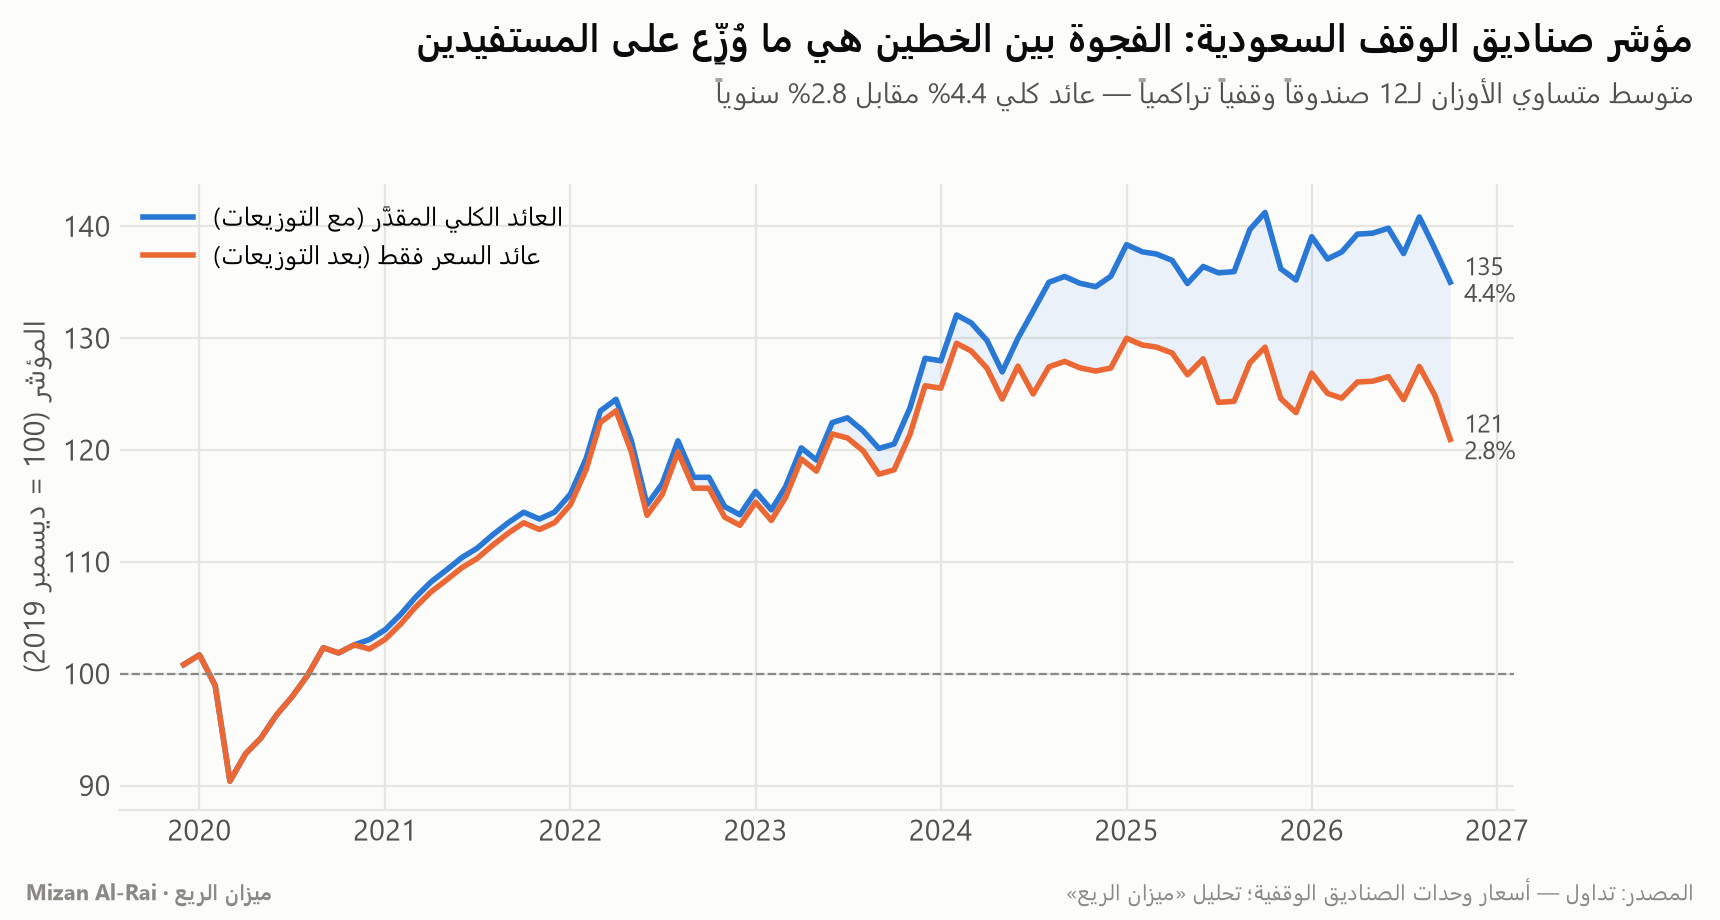

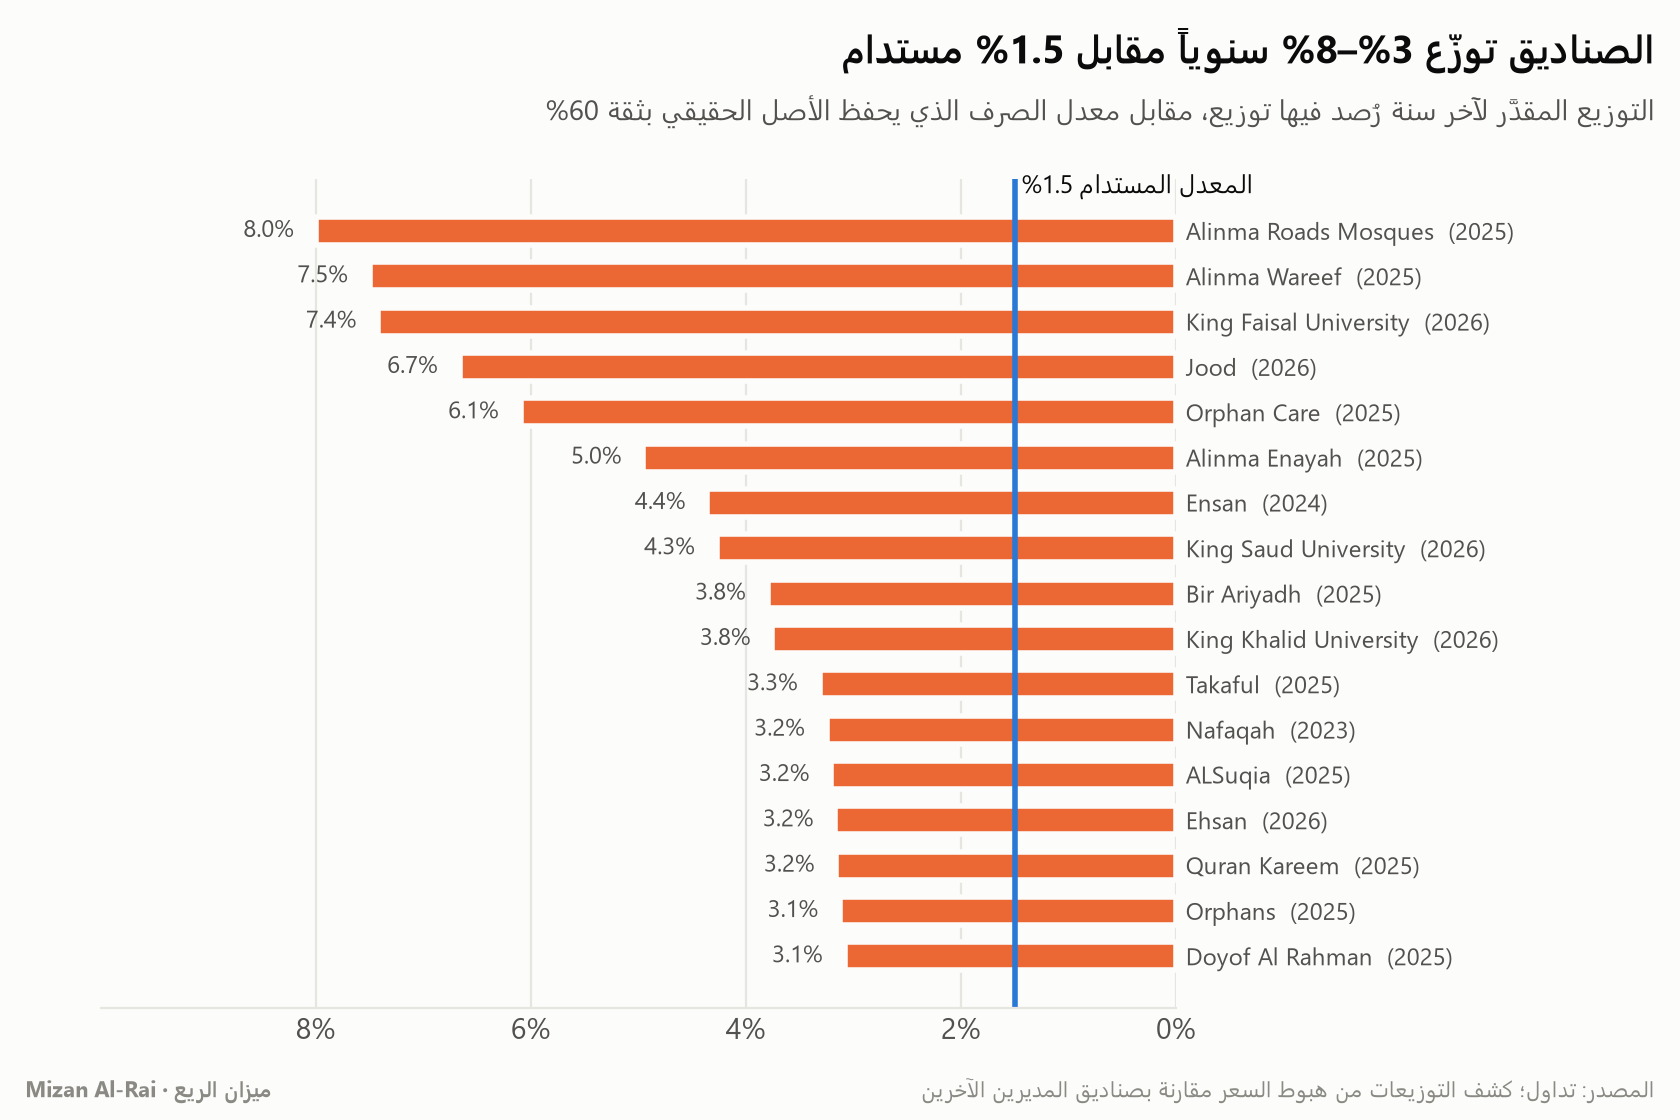

,months,ann_return,ann_vol,max_drawdown,worst_12m,best_12m
price,83.0,0.0279,0.0726,-0.1111,-0.0638,0.1717
total,83.0,0.0443,0.0703,-0.1111,-0.0549,0.1815


,symbol,fund_name,manager,fund_type,in_index,months,price_ann_return,ann_vol,total_ann_return_est,payout_events,aum_sar
1,011166,Ehsan Waqf Fund,SNB Capital,Growth,True,23,0.0246,0.0612,0.0414,1,1.701455e+09
15,014012,Ensan Endowment Fund,ALBILAD Investment Co,Growth,True,83,0.0255,0.0989,0.0393,2,3.138865e+08
2,011170,Jood Waqf Fund,SNB Capital,Growth,True,12,0.0993,0.1068,0.1725,1,2.050743e+08
21,045010,Alinma Roads Mosques Endowment Fund,Alinma Capital,Growth,True,75,0.0297,0.0656,0.0490,2,1.081713e+08
17,030030,Nafaqah Waqf Fund,Jadwa Investment,Growth,True,70,0.0521,0.0611,0.0579,1,1.026771e+08
18,045007,Alinma Wareef Endowment Fund,Alinma Capital,Growth,True,75,0.0304,0.0734,0.0593,3,8.323217e+07
22,045011,Bir Ariyadh Waqf Fund,Alinma Capital,Growth,True,71,0.0277,0.0697,0.0415,2,6.857964e+07
23,045014,King Khalid University Endowment Fund,Alinma Capital,Income and Growth,False,27,-0.0066,0.0567,0.0098,1,6.509175e+07
4,012050,Shifa Health Endowment Fund,Al Rajhi Capital,Income,False,41,-0.0013,0.0575,-0.0013,0,5.616712e+07
5,012051,Autism Associations Endowment Fund,Al Rajhi Capital,Income and Growth,False,38,0.0059,0.0636,0.0059,0,4.557332e+07


In [6]:
ix = pipeline.step_index(c, res)
show("fig04_waqf_index.png"); show("fig05_payouts_vs_sustainable.png")
display(pd.DataFrame(ix["stats"]).T.round(4))
display(res.tables["fund_summary"].round(4).head(26))

<div dir="rtl" style="text-align:right">

## 5. التنبؤ بعائد الأشهر الـ12 القادمة (مع اختبار رجعي)
خمسة نماذج قابلة للتفسير تُقارَن باختبار رجعي متدحرج (كل نقطة انطلاق ترى ماضيها فقط — مختبر آلياً ضد تسرب المستقبل).
المعيار: متوسط الخطأ المطلق لعائد 12 شهراً. اخترنا البسيط لأنه **فاز بالأرقام** لا لأنه أسهل.

</div>

,mae,rmse,bias,origins,skill_vs_zero,label_ar
model,,,,,,
trailing_36m_mean,0.0346,0.0431,0.0080,36,0.3573,متوسط آخر 36 شهراً
damped_ets,0.0375,0.0464,-0.0049,36,0.3047,تمهيد أسي بترند مخمَّد
historical_mean,0.0400,0.0479,0.0053,36,0.2570,المتوسط التاريخي
arima_ar1,0.0407,0.0487,0.0055,36,0.2448,"ARIMA(1,0,0)"
zero_return,0.0539,0.0662,-0.0503,36,0.0000,عائد صفري (مرجع ساذج)


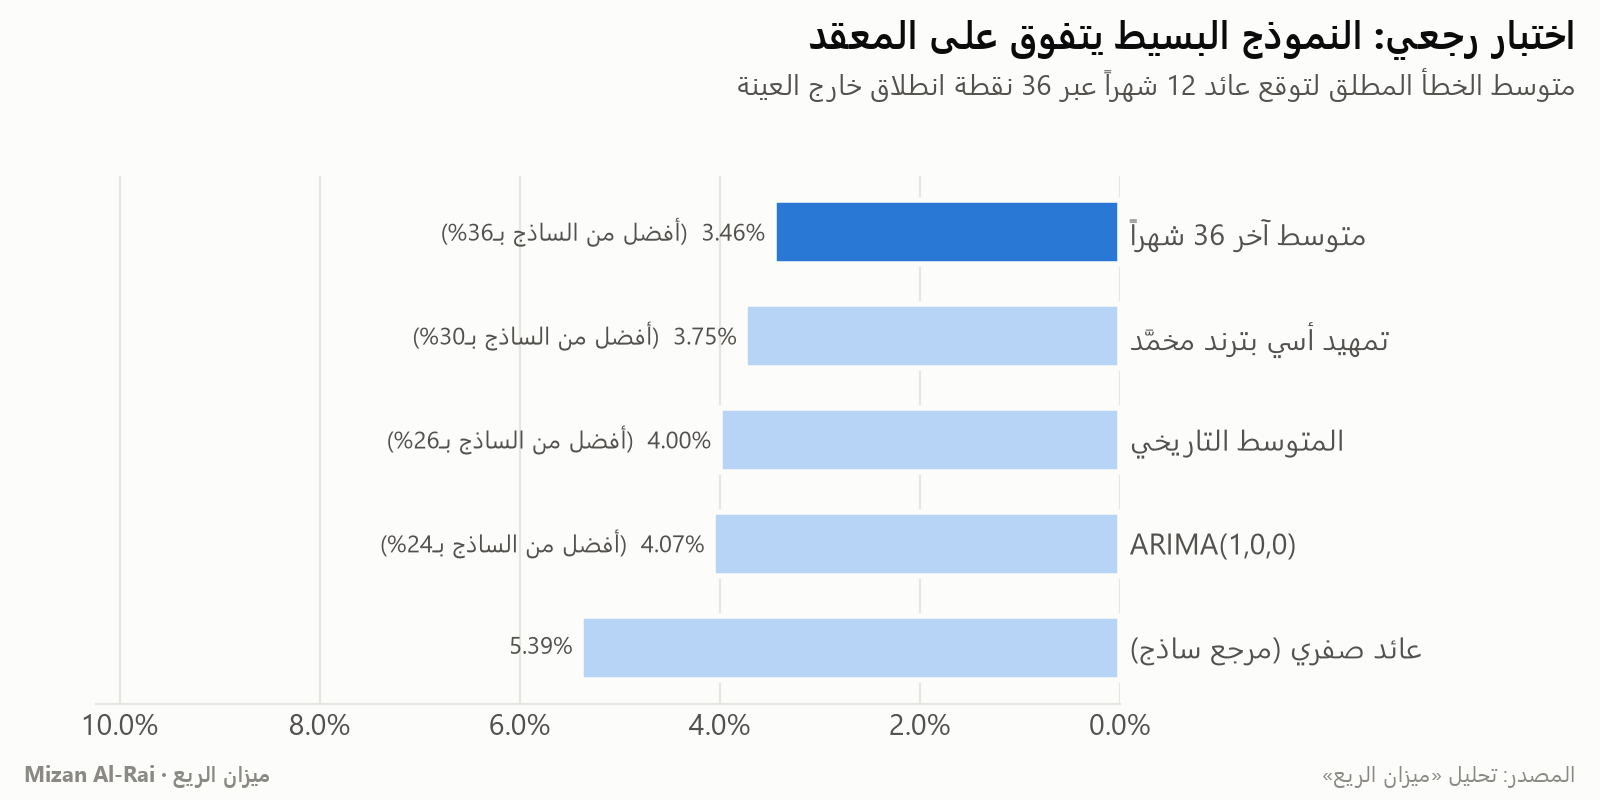

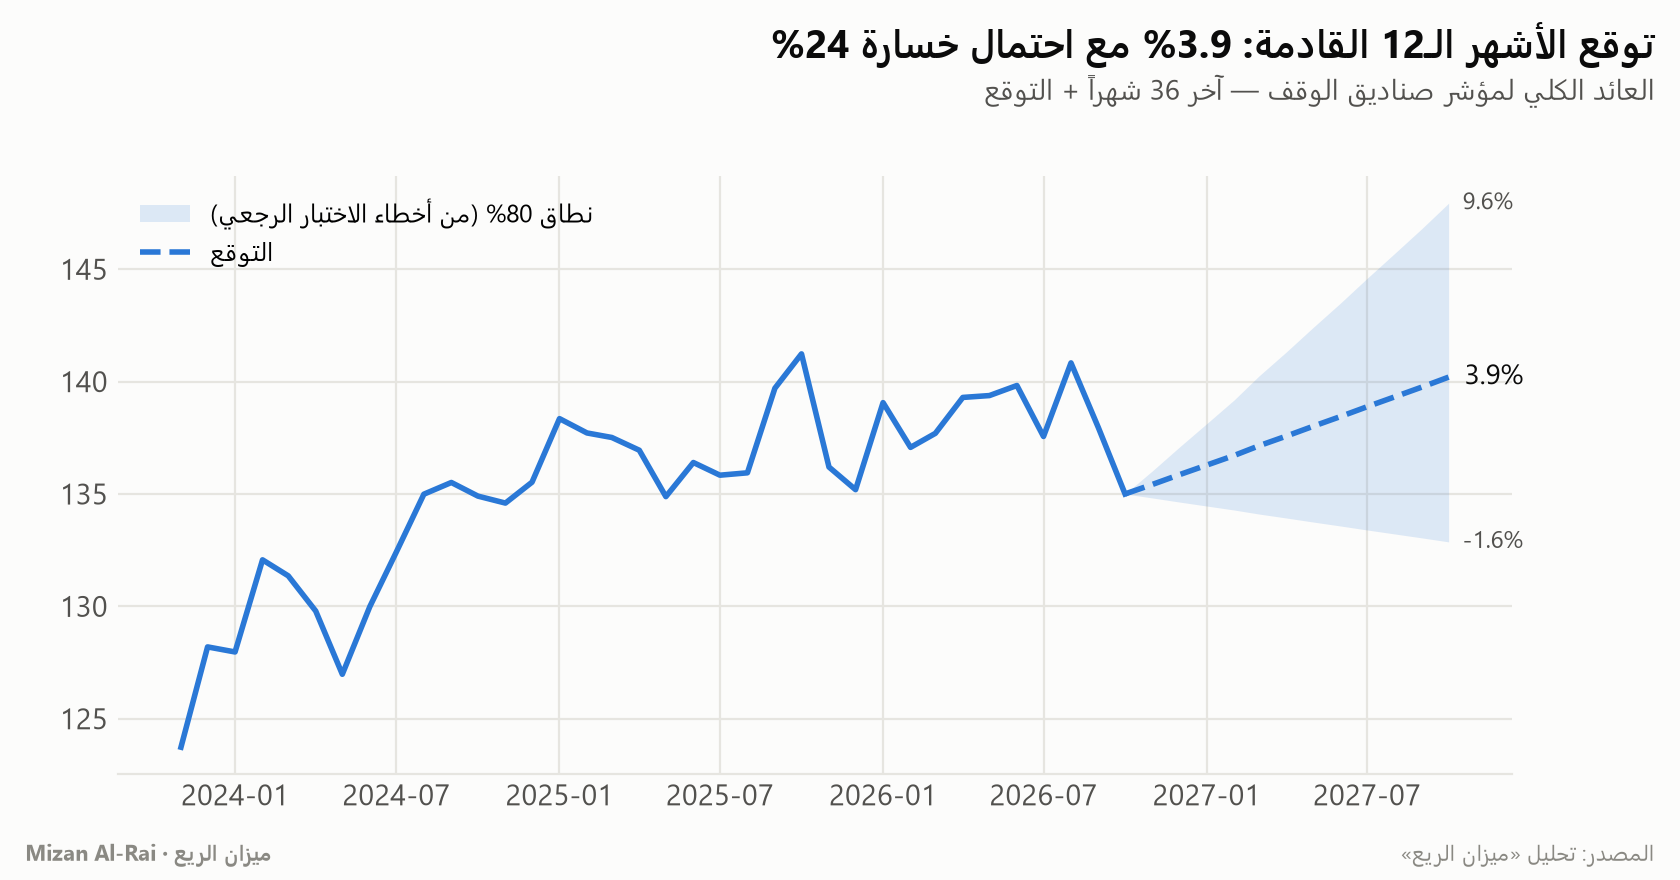

التوقع: 3.85%  نطاق 80%: [-1.58%, 9.58%]  احتمال عائد سالب: 24%


In [7]:
fc = pipeline.step_forecast(ix, res)
display(fc["scores"].round(4))
show("fig06_backtest.png"); show("fig07_forecast.png")
f = res.key["forecast"]
print(f"التوقع: {f['point_pct']:.2%}  نطاق 80%: [{f['p10_pct']:.2%}, {f['p90_pct']:.2%}]  احتمال عائد سالب: {f['bootstrap_p_loss']:.0%}")

<div dir="rtl" style="text-align:right">

## 6. القرار: معدل الصرف المستدام (محاكاة مونت كارلو)
10,000 مستقبل محتمل بإعادة معاينة كتلية ثابتة (تحافظ على ذيول التوزيع والارتباط الذاتي الفعلي)، وقاعدة صرف ممهَّدة
(نسبة من متوسط قيمة الوقف لآخر 12 ربعاً، كما تفعل أوقاف الجامعات الكبرى) وتضخم 2%. ثلاثة سيناريوهات: الأساس،
والضغط (−1% سنوياً لتحيز البقاء)، وعائد السعر فقط.

</div>

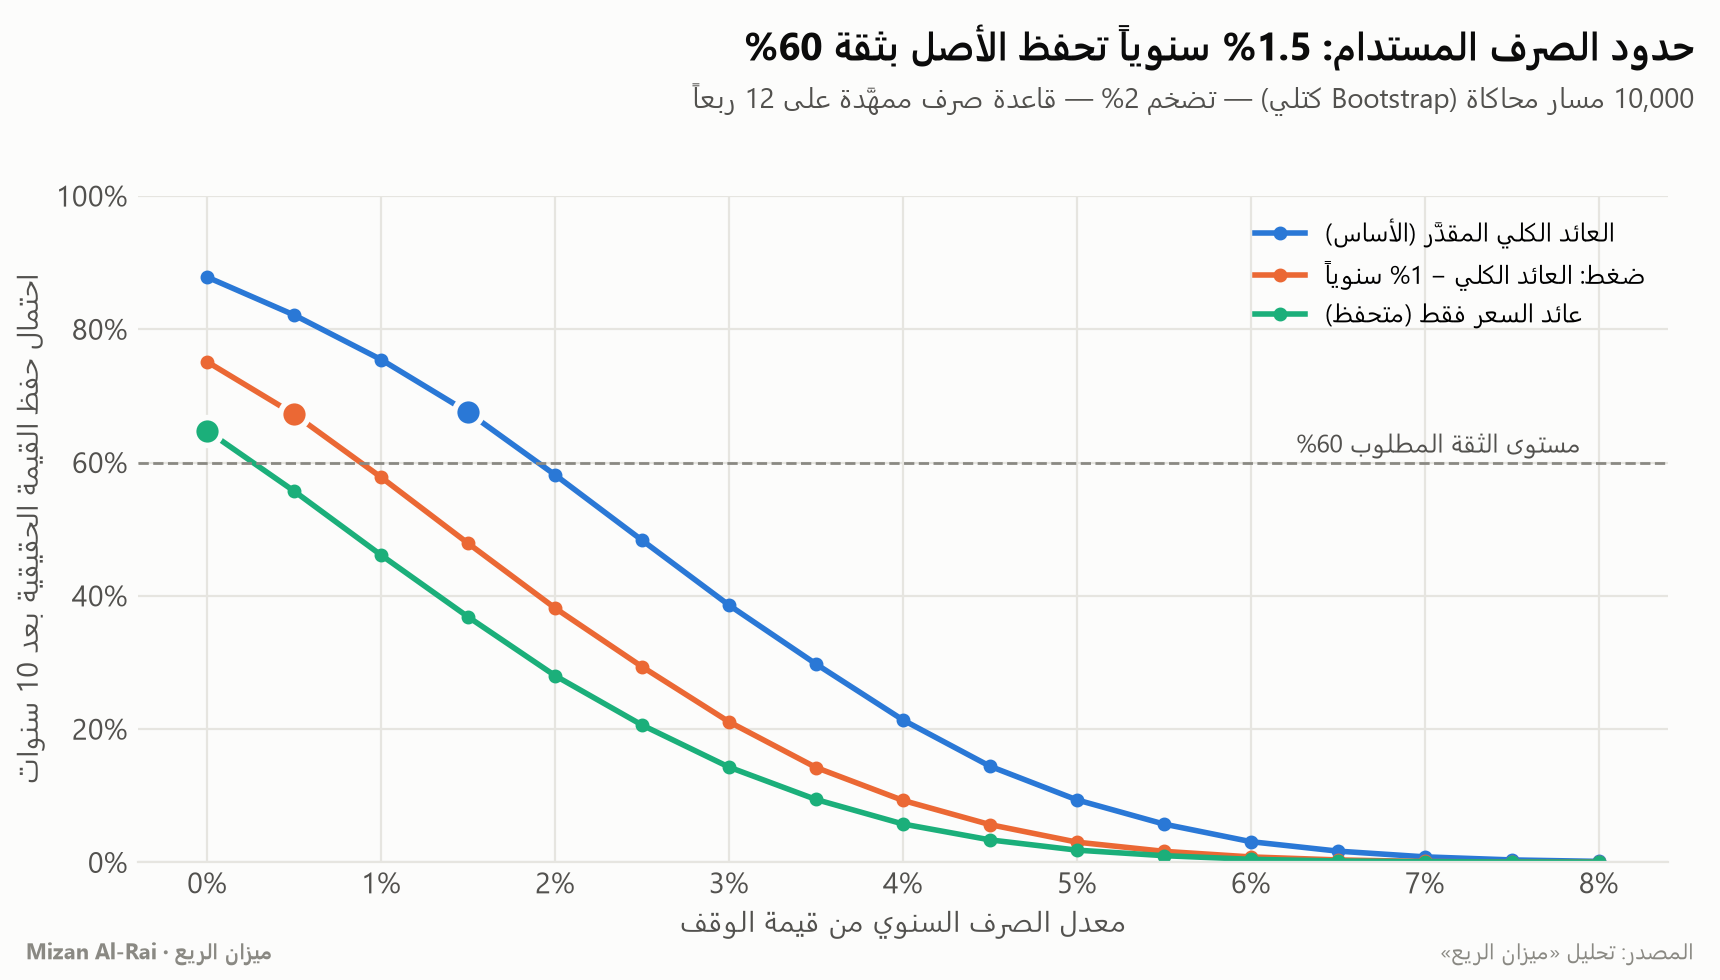

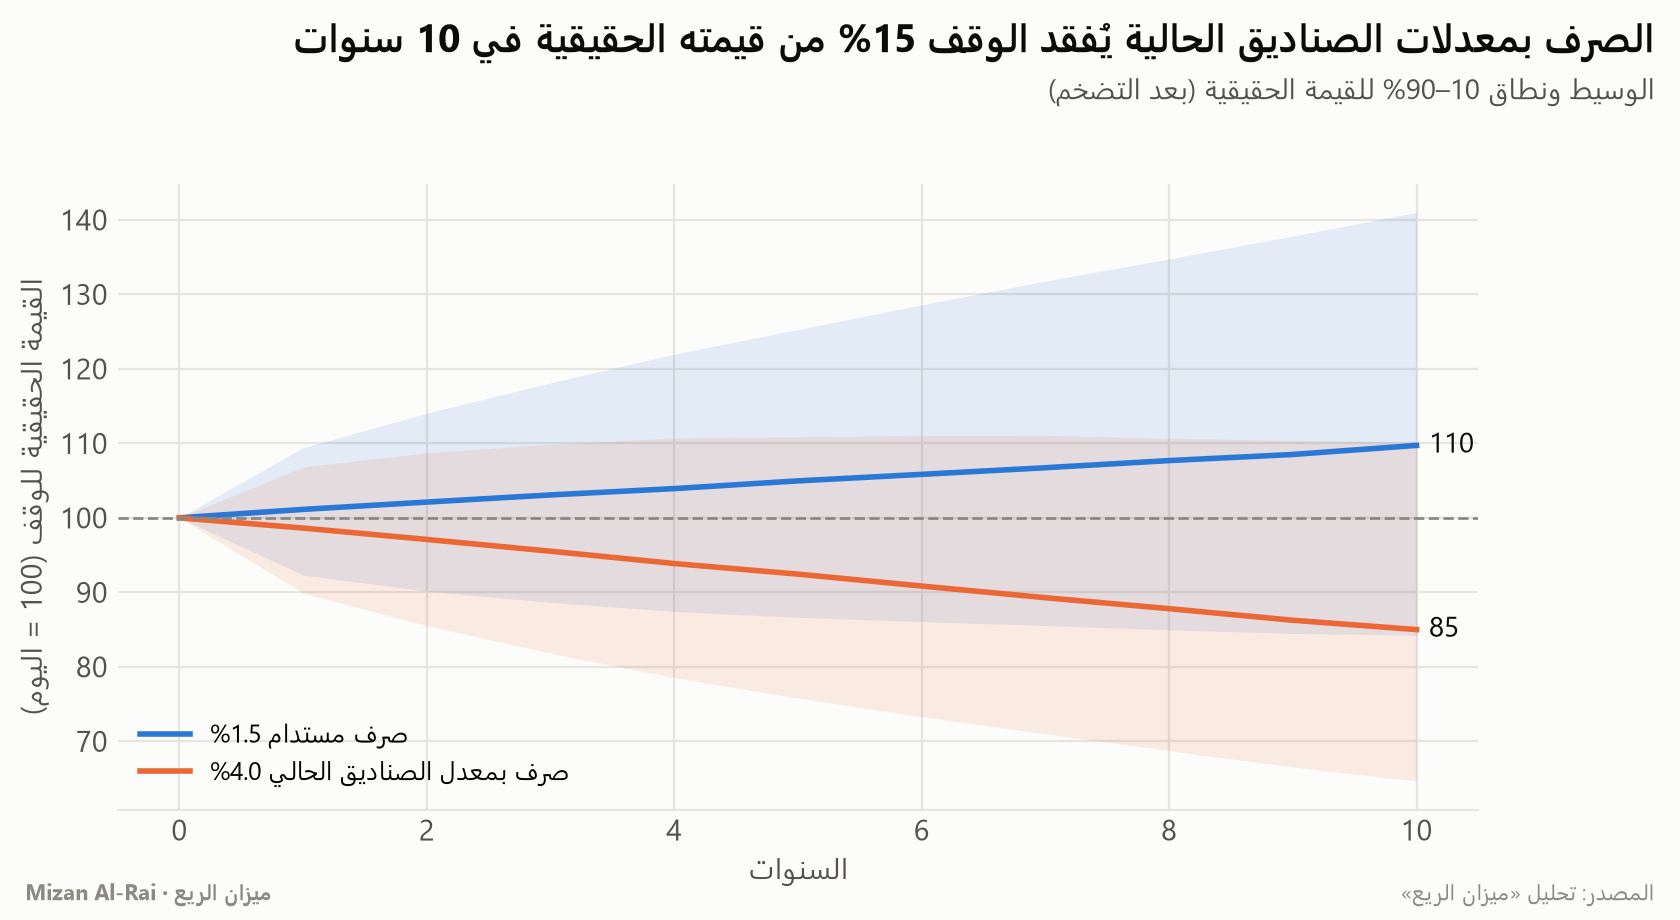

,الثقة المطلوبة,المعدل المستدام
0,50%,0.020
1,60% (الافتراضي),0.015
2,75%,0.010


,rate,p_preserve_real,median_real_final,p10_real_final,p90_real_final,median_real_spend_total,median_first_year_spend,spend_cut_prob
0,0.000,0.878,126.901,97.877,162.288,0.000,0.000,0.000
1,0.005,0.821,120.962,93.175,154.948,5.231,0.503,0.001
2,0.010,0.754,115.235,88.649,147.849,10.272,1.005,0.001
3,0.015,0.675,109.719,84.255,140.995,15.130,1.507,0.001
4,0.020,0.582,104.414,80.036,134.395,19.806,2.009,0.002
5,0.025,0.483,99.297,75.972,128.025,24.306,2.510,0.004
6,0.030,0.386,94.344,72.060,121.873,28.637,3.011,0.006
7,0.035,0.298,89.578,68.292,115.949,32.801,3.512,0.007
8,0.040,0.214,84.993,64.646,110.185,36.795,4.013,0.011
9,0.045,0.144,80.589,61.167,104.647,40.639,4.513,0.017


الصرف بمعدل الصناديق الحالي 4.0% يحفظ الأصل الحقيقي باحتمال 21% فقط


In [8]:
sp = pipeline.step_spending(ix, res)
show("fig08_spending_frontier.png"); show("fig09_real_value_paths.png")
s = res.key["spending"]
display(pd.DataFrame({"الثقة المطلوبة": ["50%","60% (الافتراضي)","75%"],
                      "المعدل المستدام": [s["rate_base_at_50"], s["rate_base"], s["rate_base_at_75"]]}))
display(res.tables["spending_frontier_base"].round(3))
print(f"الصرف بمعدل الصناديق الحالي {s['observed_payout_rate']:.1%} يحفظ الأصل الحقيقي باحتمال {s['p_preserve_at_observed']:.0%} فقط")

<div dir="rtl" style="text-align:right">

## 7. التوزيع على المصارف: حالة تطبيقية (وقف بقيمة 10 ملايين ريال)
الترتيب الشرعي: **عمارة الوقف أولاً** (10%) ← **احتياطي استقرار** حتى يبلغ صرف سنة ← **المصارف**: شروط الواقفين ثابتة
(المزيج الوطني من بيانات الهيئة افتراضياً)، والحصة المرنة (أوجه البر) تتوزع بأوزان أولوية شفافة مع حد أدنى لكل مصرف.

</div>

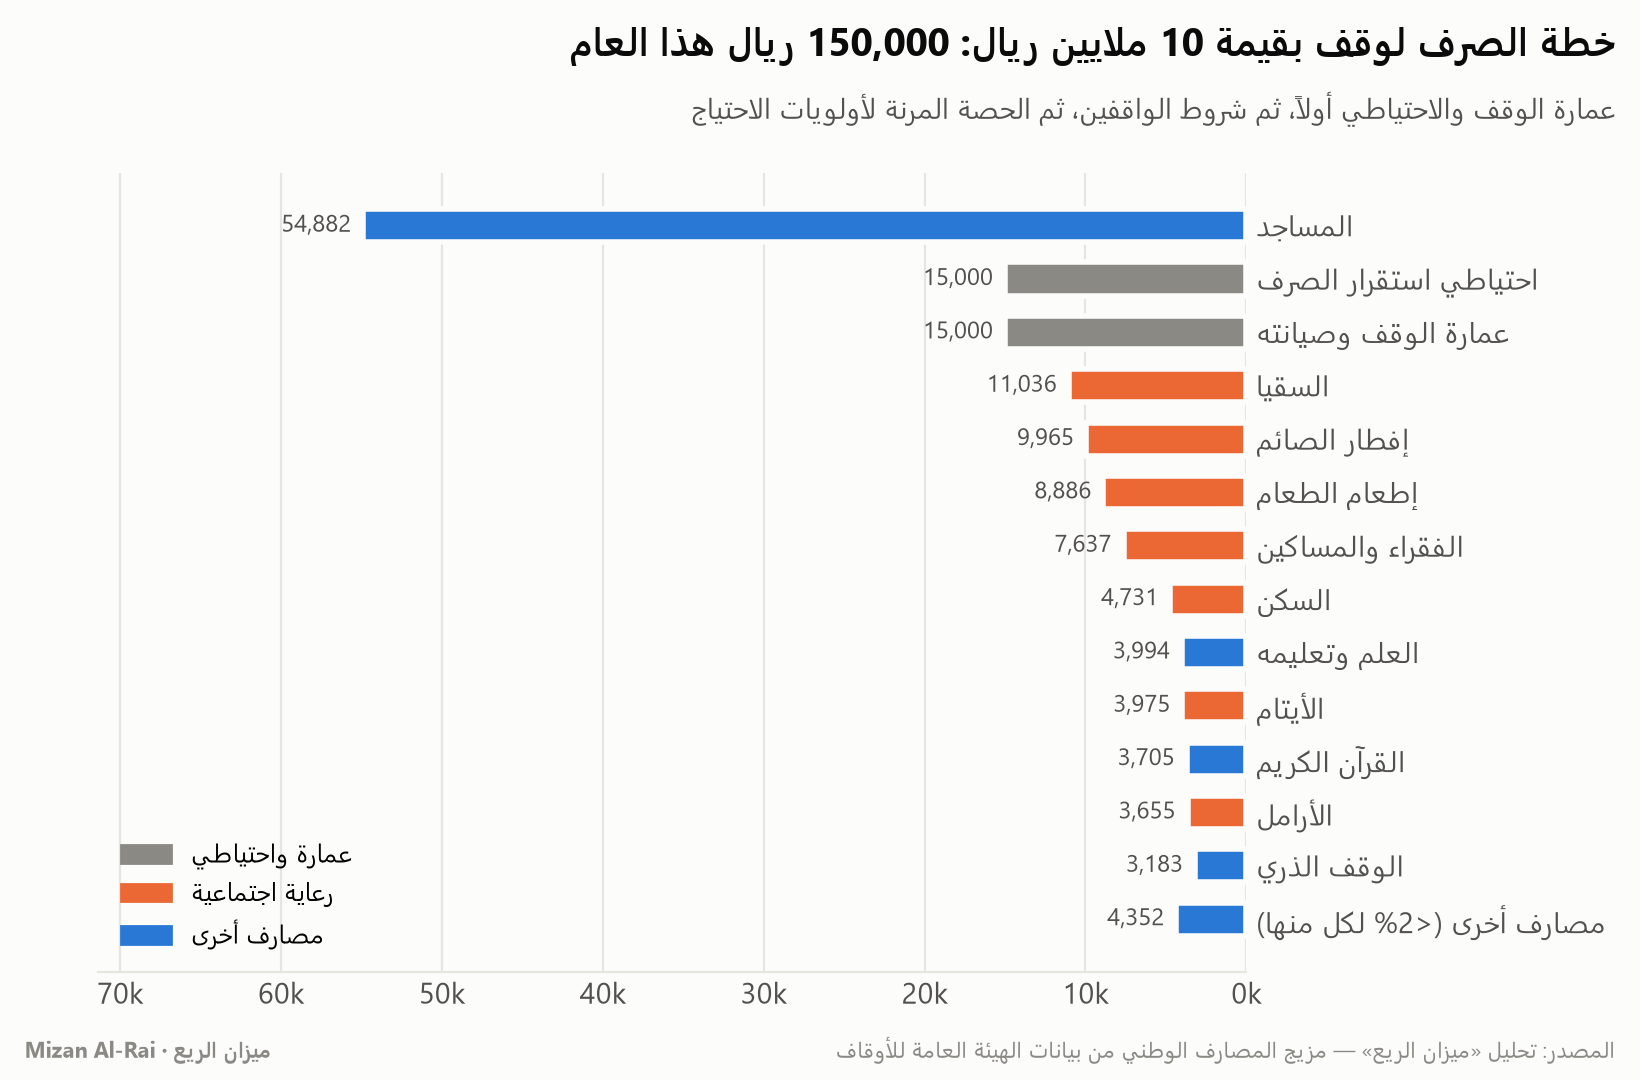

,label_ar,kind,amount,share_of_budget
0,عمارة الوقف وصيانته,waterfall,15000.000,0.100
1,احتياطي استقرار الصرف,waterfall,15000.000,0.100
2,المساجد,waqif_condition,51998.693,0.347
3,إفطار الصائم,waqif_condition,9965.371,0.066
4,السقيا,waqif_condition,7911.140,0.053
5,إطعام الطعام,waqif_condition,5519.765,0.037
6,الفقراء والمساكين,waqif_condition,3786.998,0.025
7,الوقف الذري,waqif_condition,3183.273,0.021
8,السكن,waqif_condition,1364.260,0.009
9,الحرم النبوي,waqif_condition,909.507,0.006


حصة الاحتياجات الأساسية المتكررة: 9.0% من شروط الواقفين ← 24.1% بعد توجيه الحصة المرنة


In [9]:
al = pipeline.step_allocate(c, sp, res)
show("fig10_allocation.png")
display(al["allocation"][["label_ar","kind","amount","share_of_budget"]].round(3))
a = res.key["allocation"]
print(f"حصة الاحتياجات الأساسية المتكررة: {a['social_share_before']:.1%} من شروط الواقفين ← {a['social_share_after']:.1%} بعد توجيه الحصة المرنة")

In [10]:
# حساسية: نفس الميزانية بمزيج وقف عائلي مشترك (60% ذرية + 40% أوجه البر)
from waqf import allocate
mixed = pd.Series({"family": 0.6, "general_charity": 0.4})
display(allocate.allocate(allocate.Plan(10_000_000, s["rate_base"]), mixed).round(1))

,line,kind,amount,share_of_budget
0,upkeep,waterfall,15000.0,0.1
1,reserve,waterfall,15000.0,0.1
2,family,waqif_condition,72000.0,0.5
3,poor,flexible,6681.1,0.0
4,orphans,flexible,6681.1,0.0
5,widows,flexible,5967.6,0.0
6,food,flexible,5254.1,0.0
7,housing,flexible,5254.1,0.0
8,education,flexible,5254.1,0.0
9,quran,flexible,4540.5,0.0


<div dir="rtl" style="text-align:right">

## 8. التحقق من قابلية إعادة التشغيل
نكتب المخرجات ونرسم الأشكال ثم نتأكد أن الأرقام المحفوظة تطابق ما حسبه الدفتر الآن.

</div>

In [11]:
pipeline.write_outputs(res)
pipeline.step_figures(c, sec, ix, fc, sp, al)
saved = json.loads((config.TABLES / "key_numbers.json").read_text(encoding="utf-8"))
assert saved["spending"]["rate_base"] == res.key["spending"]["rate_base"]
assert abs(saved["forecast"]["point_pct"] - res.key["forecast"]["point_pct"]) < 1e-12
print("✔ key_numbers.json يطابق الحساب الحالي")

✔ key_numbers.json يطابق الحساب الحالي


<div dir="rtl" style="text-align:right">

## 9. التوصيات
1. **اعتماد سقف صرف 1.5% سنوياً** من متوسط قيمة الوقف (12 ربعاً) كخط أساس لحفظ الأصل الحقيقي بثقة 60%، ومراجعته سنوياً بهذا النموذج.
2. **مراجعة سياسات توزيع الصناديق الوقفية:** معدلات 3–8% الحالية تعني تآكل القيمة الحقيقية؛ يُقترح ربط التوزيع بالعائد الممهَّد لا بالعائد السنوي.
3. **تخصيص عمارة الوقف واحتياطي استقرار** قبل الصرف، لامتصاص السنوات السالبة (احتمالها ≈ 24% في أي سنة).
4. **توجيه حصة "أوجه البر" (25% من المصارف)** نحو الاحتياجات المتكررة المهمَلة (الأيتام، الأرامل، الفقراء، السكن).
5. **مطالبة الجهات بنشر بيانات أدق:** صافي الأصول الفعلي ومبالغ التوزيع لكل صندوق، والمستفيدين حسب المنطقة والمصرف.

## 10. حدود التحليل (بشفافية)
- الصناديق المدرجة **وكيل** لأداء الاستثمار الوقفي، لا القوائم المالية لوقف عائلي بعينه.
- التاريخ قصير (أطوله ≈ 7 سنوات) والصناديق الحية فقط (تحيز البقاء) ← عالجناه بسيناريو ضغط.
- حجم التوزيعات **مقدَّر** من فجوة الأقران، لأن تداول لا ينشر مبالغها.
- بيانات المستفيدين وطنية لثلاث سنوات فقط، فالتوزيع يعتمد على شروط الواقفين وأوزان أولوية معلنة لا على احتياج مقاس.

</div>